# 02 — Steam parameters from thermodynamics

Goal: replace the invented v0 parameters (e_cp, e_cd, steam cost) by values computed
from steam properties (CoolProp, IAPWS-IF97 water/steam), and understand the physics behind them.

Assumptions: HP header 40 bar / 400 °C, LP header 4 bar, condenser 0.1 bar,
feedwater 105 °C, boiler efficiency 0.90, fuel 8 €/GJ, ambient T0 = 25 °C.

In [15]:
from CoolProp.CoolProp import PropsSI
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# CoolProp works in SI units: Pa, K, J/kg, J/(kg.K)
P_HP, T_HP = 40e5, 400 + 273.15
P_LP = 4e5
P_COND = 0.1e5
T0 = 25 + 273.15

h_in = PropsSI("H", "T", T_HP, "P", P_HP, "Water")
s_in = PropsSI("S", "T", T_HP, "P", P_HP, "Water")

## 1. Turbine specific power

Ideal (isentropic) expansion: $\Delta h_{is} = h_{in} - h_{out,is}$.
Real expansion: $\Delta h = \eta_{is}\,\Delta h_{is}$.
Specific power: $e\,[\text{MWh/t}] = \Delta h\,[\text{kJ/kg}] / 3600$.

In [16]:
def specific_power_mwh_t(p_out, eta_is):
    h_out_is = PropsSI("H", "S", s_in, "P", p_out, "Water")
    dh_real = eta_is * (h_in - h_out_is)      # J/kg
    return dh_real / 1000 / 3600              # J/kg -> kJ/kg -> MWh/t

rows = []
for eta in [0.75, 0.85]:
    rows.append({
        "eta_is": eta,
        "e_cp (MWh/t)": specific_power_mwh_t(P_LP, eta),
        "e_cd (MWh/t)": specific_power_mwh_t(P_COND, eta),
    })
turbines = pd.DataFrame(rows).round(3)
turbines

,eta_is,e_cp (MWh/t),e_cd (MWh/t)
0,0.75,0.110,0.223
1,0.85,0.125,0.253


## 2. Boiler steam cost

$c\,[\text{€/t}] = \dfrac{h_{steam} - h_{feedwater}}{\eta_{boiler}} \times \text{fuel price}$

In [17]:
h_fw = PropsSI("H", "T", 105 + 273.15, "P", 50e5, "Water")
ETA_BOILER, FUEL_EUR_GJ = 0.90, 8
q_gj_t = (h_in - h_fw) / 1e6                  # J/kg = kJ/t -> GJ/t
steam_cost = q_gj_t / ETA_BOILER * FUEL_EUR_GJ
print(f"Heat to steam: {q_gj_t:.2f} GJ/t -> steam cost: {steam_cost:.1f} €/t")

Heat to steam: 2.77 GJ/t -> steam cost: 24.6 €/t


## 3. Condensing turbine break-even price

The marginal tonne of HP steam comes from boiler 2 (boiler 1 is saturated),
so the condensing turbine pays off when $e_{cd}\,p > c_2$:

$$p^* = \frac{c_2}{e_{cd}}$$

In [18]:
C2 = 30  # €/t, marginal boiler (boiler 2)
turbines["break-even (€/MWh)"] = (C2 / turbines["e_cd (MWh/t)"]).round(1)
turbines

,eta_is,e_cp (MWh/t),e_cd (MWh/t),break-even (€/MWh)
0,0.75,0.110,0.223,134.5
1,0.85,0.125,0.253,118.6


## 4. Why e_cd ≈ 2 × e_cp

$\Delta h_{is} = \int v\,dp$: the energy of an expansion is the area under the curve $v(p)$.
The specific volume explodes at low pressure, so the last few bar under vacuum
are worth as much as the first 36 bar.

,p (bar),v (m3/kg),cumulative dh_is from 40 bar (kJ/kg)
0,40.0,0.073,0.000
1,4.0,0.451,528.152
2,0.1,11.976,1069.965


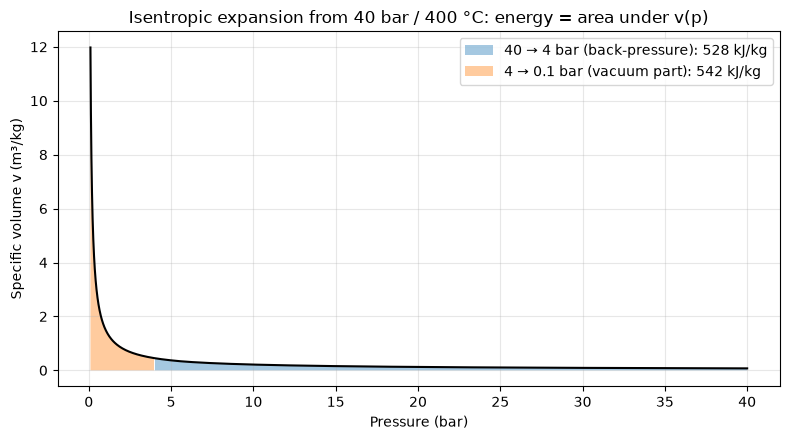

In [19]:
pressures = np.geomspace(P_HP, P_COND, 400)
v = np.array([1 / PropsSI("D", "S", s_in, "P", p, "Water") for p in pressures])

table = pd.DataFrame({
    "p (bar)": [40, 4, 0.1],
    "v (m3/kg)": [1 / PropsSI("D", "S", s_in, "P", p, "Water") for p in [P_HP, P_LP, P_COND]],
    "cumulative dh_is from 40 bar (kJ/kg)": [
        (h_in - PropsSI("H", "S", s_in, "P", p, "Water")) / 1000 for p in [P_HP, P_LP, P_COND]
    ],
}).round(3)
display(table)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(pressures / 1e5, v, color="black")
hi = pressures >= P_LP
ax.fill_between(pressures[hi] / 1e5, v[hi], alpha=0.4, label="40 → 4 bar (back-pressure): 528 kJ/kg")
ax.fill_between(pressures[~hi] / 1e5, v[~hi], alpha=0.4, label="4 → 0.1 bar (vacuum part): 542 kJ/kg")
ax.set_xlabel("Pressure (bar)")
ax.set_ylabel("Specific volume v (m³/kg)")
ax.set_title("Isentropic expansion from 40 bar / 400 °C: energy = area under v(p)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("../docs/steam_v_p.png", dpi=150)

## 5. Exergy balance: turbine vs let-down valve

$\psi_1 - \psi_2 = w + T_0\,s_{gen}$ (adiabatic device, Gouy–Stodola)

In [20]:
ETA = 0.75
h_out_is = PropsSI("H", "S", s_in, "P", P_LP, "Water")

# Turbine: real outlet state
h_t = h_in - ETA * (h_in - h_out_is)
s_t = PropsSI("S", "H", h_t, "P", P_LP, "Water")
# Valve: isenthalpic
h_v = h_in
s_v = PropsSI("S", "H", h_v, "P", P_LP, "Water")

def exergy_row(name, h_out, s_out, w):
    dpsi = (h_in - h_out) - T0 * (s_in - s_out)
    destroyed = T0 * (s_out - s_in)
    return {"device": name,
            "T_out (°C)": PropsSI("T", "H", h_out, "P", P_LP, "Water") - 273.15,
            "s_gen (kJ/kg/K)": (s_out - s_in) / 1000,
            "exergy drop (kJ/kg)": dpsi / 1000,
            "work (kJ/kg)": w / 1000,
            "destroyed T0*s_gen (kJ/kg)": destroyed / 1000,
            "check: drop - work - destroyed": (dpsi - w - destroyed) / 1000}

exergy = pd.DataFrame([
    exergy_row("back-pressure turbine", h_t, s_t, h_in - h_t),
    exergy_row("let-down valve", h_v, s_v, 0.0),
]).round(1)
exergy

,device,T_out (°C),s_gen (kJ/kg/K),exergy drop (kJ/kg),work (kJ/kg),destroyed T0*s_gen (kJ/kg),check: drop - work - destroyed
0,back-pressure turbine,179.9,0.3,488.2,396.1,92.1,0.0
1,let-down valve,371.5,1.0,309.7,0.0,309.7,0.0


## 6. Answers

**Q1 — Are the v0 parameters realistic?**
Yes, in order of magnitude. With η_is = 0.75: e_cp = 0.110 MWh/t (v0: 0.08, conservative),
e_cd = 0.223 MWh/t (v0: 0.20), steam cost = 24.6 €/t (v0: 25). In v1 these parameters will be
computed from header pressures, temperatures and efficiencies instead of being typed in.

**Q2 — Effect of η_is = 0.85 on the break-even price.**
The break-even is $p^* = c_2 / e_{cd}$. It uses $c_2 = 30$ €/t, the cost of the *marginal* boiler,
not the cheapest one. A better turbine produces more MWh per tonne, so the break-even goes **down**:
150 €/MWh (v0) → 134.5 €/MWh (η = 0.75) → 118.6 €/MWh (η = 0.85).
e_cp does not appear in the formula: F_cp is fixed by the LP demand, so a better back-pressure
turbine reduces grid purchase but does not change the condensing turbine decision.
A decision only depends on the parameters *at the margin*.

**Q3 — Why e_cd ≈ 2 × e_cp?**
The expansion energy is $\int v\,dp$, the area under $v(p)$. The specific volume explodes at low
pressure (0.07 m³/kg at 40 bar, 0.45 at 4 bar, 12 at 0.1 bar). What matters for a gas is not the
pressure *difference* but the pressure *ratio*: 10 for the back-pressure turbine (40 → 4 bar),
400 for the condensing turbine (40 → 0.1 bar). The last 3.9 bar under vacuum (ratio 40) produce
542 kJ/kg, as much as the first 36 bar (528 kJ/kg). This is why condensers run under vacuum, and
why a condensing turbine loses power in summer when the vacuum degrades.

**Exergy.** The turbine converts 81 % of the exergy it consumes into work. The let-down valve
destroys 100 % of it (≈ 310 kJ/kg): energy is conserved (h_out = h_in), but the capacity to
produce electricity is lost.